# 04 Criteria Aggregation

Aggregates the criteria of one MCDM matrix with the weights computed for it in 03_Criteria_Weighting into a suitability
score for every candidate cell with five MCDM methods: WSM, WASPAS, TOPSIS, MOORA and Compromise Programming (CP).
The scores are classified into five suitability classes, exported as maps and compared across methods.

In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
import jenkspy
import rasterio
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from scipy.stats import binomtest, kendalltau, rankdata, spearmanr

from gis_mcdm import (ask_choice, choose_run, crs_label, find_runs, is_baseline, load_config, read_matrix_info,
                      study_area_file, transformed)

cfg, P = load_config()  # config.toml
WEIGHTS_DIR, POLYGON_DIR, SCORES_DIR, MAPS_DIR, FIGURES_DIR = P.weights, P.study_area, P.scores, P.maps, P.figures
for folder in (SCORES_DIR, MAPS_DIR, FIGURES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# Figures are drawn at their printed size (letter page, 6.5 in text width) with 9 pt Palatino.
# For Word, insert the saved .svg (vector) or .png (600 dpi) file at 100 % so the text stays at 9 pt.
TEXT_WIDTH = 6.5
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Palatino Linotype", "Palatino", "Book Antiqua", "TeX Gyre Pagella", "DejaVu Serif"],
    "mathtext.fontset": "custom", "mathtext.rm": "serif",
    "font.size": 8, "axes.titlesize": 8, "axes.labelsize": 8,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "legend.title_fontsize": 8,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "figure.dpi": 200,  # sharper preview in the notebook
    "savefig.dpi": 600, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
})


def save_figure(fig, name):
    for ext in ("png", "svg"):
        fig.savefig(FIGURES_DIR / f"{name}.{ext}")

In [ ]:
# Run to aggregate (press Enter to keep the default shown in brackets: the run of [run] in config.toml)
WEIGHT_METHODS = {"EWM": "EWM_Weight", "CRITIC": "CRITIC_Weight"}


def weights_path(run):
    return WEIGHTS_DIR / f"Criteria_Weights_{run.tag}.csv"


run = choose_run(cfg, find_runs(cfg, P), usable=lambda r: weights_path(r).exists(),
                 unusable_note="no weights: run 03 first")
MATRIX_PATH, WEIGHTS_PATH = run.matrix, weights_path(run)
SCENARIO, ALPHA_TAG, RES_TAG = run.scenario, run.alpha, run.res
WEIGHT_METHOD = ask_choice("Which weights?", list(WEIGHT_METHODS), cfg["run"]["weights"], cfg["run"]["interactive"])

# Four classification methods are compared for the baseline run of [run] (compare_classifications in config.toml);
# the maps always use Jenks
RUN_CLASSIFICATION_COMPARISON = {"always": True, "never": False}.get(cfg["run"]["compare_classifications"],
                                                                     is_baseline(cfg, run))

ANCHOR_PATH = POLYGON_DIR / f"anchor_grid_{RES_TAG}.tif"  # grid of the matrix, from 01_Data_Preprocessing
if not ANCHOR_PATH.exists():
    raise FileNotFoundError(f"{ANCHOR_PATH.name} not found. Run 01_Data_Preprocessing at {RES_TAG} first.")

RUN_TAG = f"{WEIGHT_METHOD}_{run.tag}"
print(f"\nRun: {SCENARIO}, alpha {ALPHA_TAG}, {RES_TAG}, {WEIGHT_METHOD} weights ({MATRIX_PATH.name})")


def table_path(name):
    return SCORES_DIR / f"{name}_{RUN_TAG}.csv"


def map_path(name):
    return MAPS_DIR / f"Suitability_Map_{name}_{RUN_TAG}.tif"

## 1. Matrix and weights

In [ ]:
raw_df = pd.read_csv(MATRIX_PATH)
weights_df = pd.read_csv(WEIGHTS_PATH)
CRIT = {c["column"]: c for c in read_matrix_info(MATRIX_PATH)}  # criteria of the matrix, written by 02
crit_cols = list(CRIT)

lookup = weights_df.set_index("Criterion")[WEIGHT_METHODS[WEIGHT_METHOD]]
missing = [col for col in crit_cols if col not in lookup.index]
if missing:
    raise KeyError(f"Criteria missing from {WEIGHTS_PATH.name}: {missing}. Re-run 03_Criteria_Weighting for this matrix.")
w = lookup[crit_cols].to_numpy(dtype=float)
is_cost = np.array([CRIT[col]["type"] == "cost" for col in crit_cols])

# Same scale as in 03_Criteria_Weighting: the criterion's transform (e.g. log), other values unchanged
X = np.column_stack([transformed(raw_df[col], CRIT[col]) for col in crit_cols])
rows_idx, cols_idx = raw_df["Row_Idx"].to_numpy(int), raw_df["Col_Idx"].to_numpy(int)  # grid position of each cell
del raw_df

## 2. Suitability scores

In [ ]:
def aggregate(X, w, is_cost, lam=0.5):
    """Scores of the five MCDM methods, built one criterion at a time to keep memory low."""
    n = len(X)
    wsm, wpm, moora = np.zeros(n), np.ones(n), np.zeros(n)
    d_best, d_worst, l_inf = np.zeros(n), np.zeros(n), np.full(n, -np.inf)
    for j in range(X.shape[1]):
        x, wj, cost = X[:, j], w[j], is_cost[j]
        lo, hi = x.min(), x.max()
        span = hi - lo
        # Linear normalization (WSM, WASPAS): benefit x / max, cost 1 - x / max. It needs x >= 0, so a criterion
        # with negative values (e.g. the log of gravity values below 1) is shifted to start at 0
        x_lin = x - lo if lo < 0 else x
        hi_lin = x_lin.max() or 1.0
        r = 1 - x_lin / hi_lin if cost else x_lin / hi_lin
        wsm += r * wj
        wpm *= r ** wj
        # Weighted vector normalization (TOPSIS, MOORA)
        length = np.sqrt(np.sum(x ** 2))
        v = (x / length if length else np.zeros(n)) * wj
        best, worst = (v.min(), v.max()) if cost else (v.max(), v.min())
        d_best += (v - best) ** 2
        d_worst += (v - worst) ** 2
        moora += -v if cost else v
        # Weighted distance to the ideal (CP)
        l_inf = np.maximum(l_inf, wj * (((x - lo) if cost else (hi - x)) / (span if span else 1.0)))
    d_best, d_worst = np.sqrt(d_best), np.sqrt(d_worst)
    return {
        "WSM": wsm,
        "WASPAS": lam * wsm + (1 - lam) * wpm,
        "TOPSIS": d_worst / (d_best + d_worst),
        "MOORA": (moora - moora.min()) / (moora.max() - moora.min()),
        "CP": (l_inf.max() - l_inf) / (l_inf.max() - l_inf.min()),
    }


negative = [col for j, col in enumerate(crit_cols) if X[:, j].min() < 0]
if negative:
    print(f"Shifted to start at 0 for the linear normalization of WSM and WASPAS (negative values): {', '.join(negative)}")
scores_df = pd.DataFrame(aggregate(X, w, is_cost))
methods = list(scores_df.columns)
del X

S = scores_df.to_numpy()
spearman_df = pd.DataFrame(spearmanr(S).statistic, index=methods, columns=methods)  # Spearman's rho, method x method

## 3. Score distributions

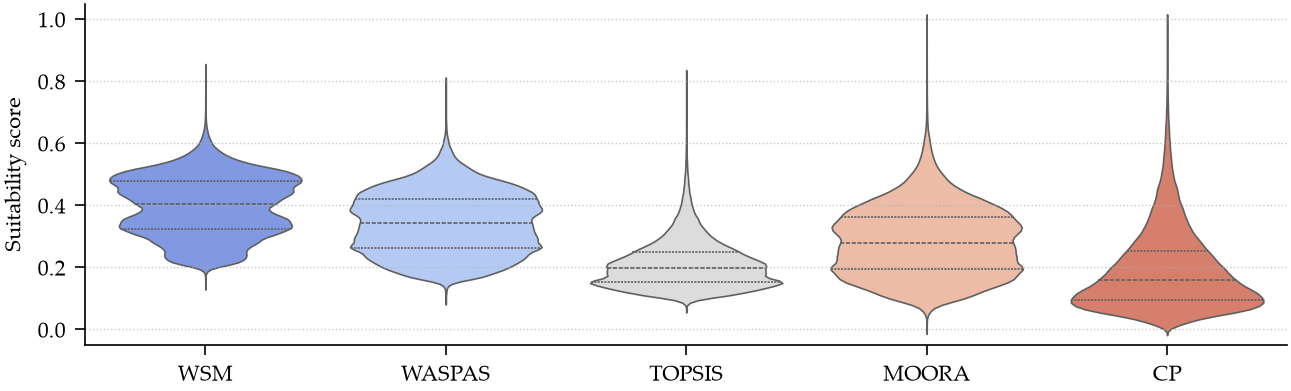

In [5]:
# Violins from a fixed random sample of 500,000 cells: the kernel density of all cells gives the same shape, far slower
sample = scores_df.sample(n=min(500_000, len(scores_df)), random_state=42).melt(var_name="Method", value_name="Score")

fig, ax = plt.subplots(figsize=(TEXT_WIDTH, 2), layout="constrained")
sns.violinplot(data=sample, x="Method", y="Score", hue="Method", legend=False, inner="quartile",
               palette="coolwarm", linewidth=0.6, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("Suitability score")
ax.set_ylim(-0.05, 1.05)
ax.grid(axis="y", linestyle=":", linewidth=0.5, alpha=0.7)
sns.despine(ax=ax)

save_figure(fig, f"MCDM_Violin_Distributions_{RUN_TAG}")
plt.show()

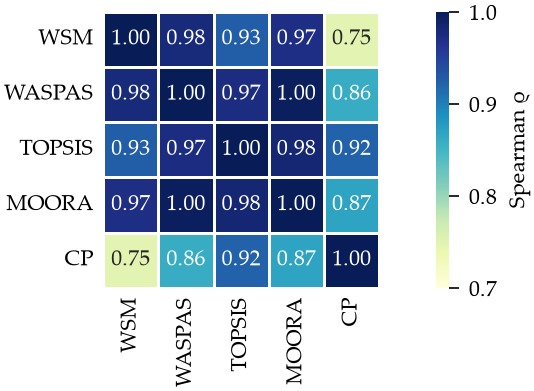

In [6]:
fig, ax = plt.subplots(figsize=(TEXT_WIDTH, 2.0), layout="constrained")
vmin = min(0.8, np.floor(spearman_df.to_numpy().min() * 10) / 10)  # colour scale starts at 0.8 unless a value is lower
sns.heatmap(spearman_df, annot=True, fmt=".2f", annot_kws={"fontsize": 8}, cmap="YlGnBu", vmin=vmin, vmax=1.0,
            square=True, linewidths=0.5, cbar_kws={"label": "Spearman ρ", "shrink": 1.0}, ax=ax)
ax.tick_params(length=0, rotation=90)
ax.tick_params(axis="y", rotation=0)

save_figure(fig, f"MCDM_Spearman_Correlation_{RUN_TAG}")
plt.show()

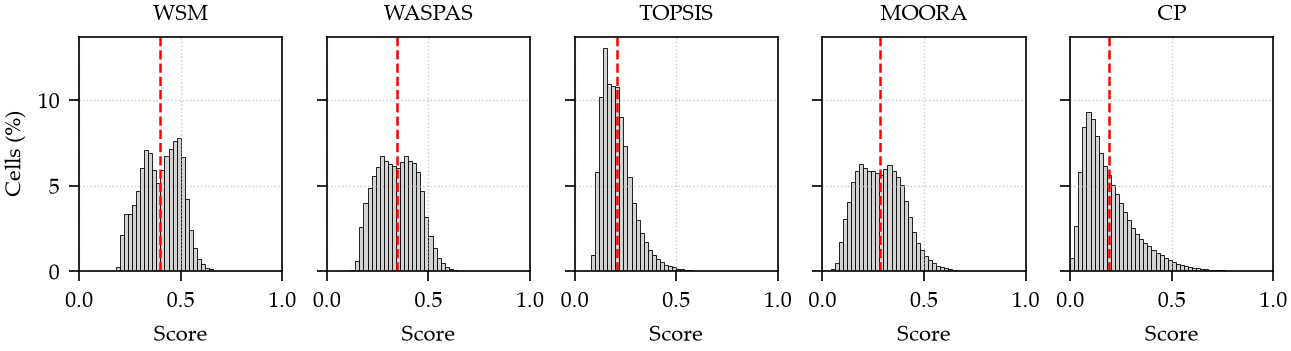

In [7]:
fig, axes = plt.subplots(1, len(methods), figsize=(TEXT_WIDTH, 1.8), sharex=True, sharey=True, layout="constrained")
for ax, m in zip(axes, methods):
    values = scores_df[m]
    counts, edges = np.histogram(values, bins=50, range=(0, 1))
    ax.bar(edges[:-1], 100 * counts / len(values), width=np.diff(edges), align="edge",
           color="lightgray", edgecolor="black", linewidth=0.3)
    ax.axvline(values.mean(), color="red", linestyle="--", linewidth=0.9)
    ax.set_title(m)
    ax.set_xlim(0, 1)
    ax.set_xlabel("Score")
    ax.grid(True, linestyle=":", linewidth=0.5, alpha=0.7)
axes[0].set_ylabel("Cells (%)")

save_figure(fig, f"MCDM_Score_Histograms_{RUN_TAG}")
plt.show()

In [8]:
q = scores_df.quantile([0.25, 0.5, 0.75])
stats_df = pd.DataFrame({
    "mean": scores_df.mean(), "median": q.loc[0.5], "std": scores_df.std(), "variance": scores_df.var(),
    "iqr": q.loc[0.75] - q.loc[0.25], "min": scores_df.min(), "max": scores_df.max(),
    "skewness": scores_df.skew(), "kurtosis": scores_df.kurt(),
})
stats_df.to_csv(table_path("Score_Statistics"), index_label="Method")
display(stats_df.round(4))

,mean,median,std,variance,iqr,min,max,skewness,kurtosis
WSM,0.3992,0.4051,0.0961,0.0092,0.1530,0.1411,0.8421,-0.0758,-0.8145
WASPAS,0.3435,0.3423,0.0986,0.0097,0.1567,0.0931,0.7982,0.1332,-0.7460
TOPSIS,0.2102,0.1968,0.0773,0.0060,0.0967,0.0647,0.8251,1.2844,2.5654
MOORA,0.2838,0.2788,0.1115,0.0124,0.1692,0.0000,1.0000,0.3687,-0.2135
CP,0.1918,0.1581,0.1298,0.0169,0.1590,0.0000,1.0000,1.3886,2.4424


## 4. Suitability classification

In [9]:
CLASS_LABELS = ["Non-Suitable", "Low Suitable", "Moderately Suitable", "Suitable", "Highly Suitable"]
CLASSIFICATIONS = {"Jenks": "Jenks Natural Breaks", "Fixed": "Common Fixed Thresholds",
                   "Quant": "Quantile Thresholds", "StdDev": "Standardized Thresholds"}

with rasterio.open(ANCHOR_PATH) as src:
    anchor, anchor_meta = src.read(1), src.meta.copy()
CELL_AREA_KM2 = abs(anchor_meta["transform"].a * anchor_meta["transform"].e) / 1e6


def jenks_classify(scores, sample_size=50000):
    """Jenks Natural Breaks fitted on a random sample (for speed) and applied to every cell."""
    sample = scores.sample(n=sample_size, random_state=42) if len(scores) > sample_size else scores
    breaks = jenkspy.jenks_breaks(sample, n_classes=len(CLASS_LABELS))
    breaks[0], breaks[-1] = scores.min() - 1e-9, scores.max() + 1e-9
    return pd.cut(scores, bins=breaks, labels=CLASS_LABELS)


def class_table(classes_by_method, classification):
    """Cells, area and % of the candidate area in each class, per method."""
    rows = []
    for method, classes in classes_by_method.items():
        counts = classes.value_counts().reindex(CLASS_LABELS, fill_value=0)
        rows += [{"Classification": classification, "Method": method, "Class": cls, "Cells": n,
                  "Area_km2": n * CELL_AREA_KM2, "Pct_Candidate_Area": 100 * n / counts.sum()}
                 for cls, n in counts.items()]
    return pd.DataFrame(rows)


classified = {"Jenks": {m: jenks_classify(scores_df[m]) for m in methods}}
if RUN_CLASSIFICATION_COMPARISON:
    classified |= {"Fixed": {}, "Quant": {}, "StdDev": {}}
    for m in methods:
        s = scores_df[m]
        mean, std = s.mean(), s.std()
        classified["Fixed"][m] = pd.cut((s - s.min()) / (s.max() - s.min()), [-np.inf, 0.2, 0.4, 0.6, 0.8, np.inf],
                                        labels=CLASS_LABELS)
        classified["Quant"][m] = pd.qcut(s, q=5, labels=CLASS_LABELS, duplicates="drop")
        classified["StdDev"][m] = pd.cut(s, [-np.inf, mean - std, mean, mean + std, mean + 2 * std, np.inf],
                                         labels=CLASS_LABELS)

shares = pd.concat([class_table(classified[key], CLASSIFICATIONS[key]) for key in classified], ignore_index=True)
shares.to_csv(table_path("Class_Shares"), index=False)
display(shares.pivot_table(index=["Classification", "Method"], columns="Class", values="Pct_Candidate_Area",
                           sort=False)[CLASS_LABELS].round(2))

Class                        Non-Suitable  Low Suitable  Moderately Suitable  \
Classification       Method                                                    
Jenks Natural Breaks WSM            15.73         25.55                21.56   
                     WASPAS         19.11         24.35                23.28   
                     TOPSIS         33.42         30.89                22.40   
                     MOORA          21.38         25.63                25.13   
                     CP             36.91         29.49                19.91   

Class                        Suitable  Highly Suitable  
Classification       Method                             
Jenks Natural Breaks WSM        24.86            12.30  
                     WASPAS     22.80            10.45  
                     TOPSIS     10.31             2.99  
                     MOORA      21.15             6.71  
                     CP         10.50             3.19

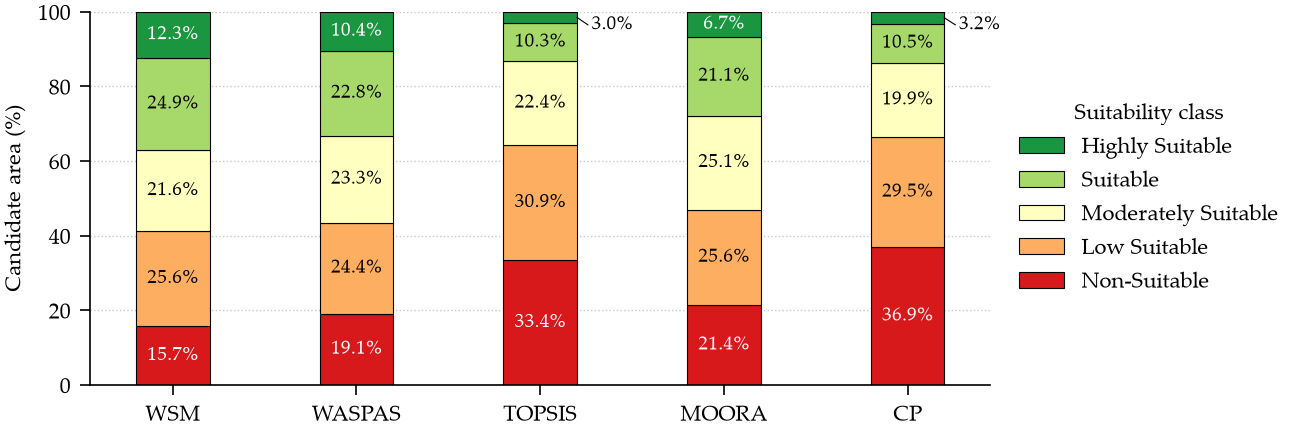

In [10]:
CLASS_COLORS = ["#d7191c", "#fdae61", "#ffffbf", "#a6d96a", "#1a9641"]

jenks_pct = (shares[shares["Classification"] == CLASSIFICATIONS["Jenks"]]
             .pivot(index="Method", columns="Class", values="Pct_Candidate_Area")
             .loc[methods, CLASS_LABELS])

fig, ax = plt.subplots(figsize=(TEXT_WIDTH, 2.2), layout="constrained")

jenks_pct.plot.bar(stacked=True, color=CLASS_COLORS, edgecolor="black", linewidth=0.4, width=0.4, ax=ax, legend=False)
for bars, color in zip(ax.containers, CLASS_COLORS):  # label inside segments of at least 5 %
    ax.bar_label(bars, labels=[f"{v:.1f}%" if v >= 5 else "" for v in bars.datavalues], label_type="center",
                 fontsize=7, color="white" if color in ("#d7191c", "#1a9641") else "black")
# Thinner segments: label beside the bar with a leader line, at least GAP apart and inside the 0-100 axis
GAP = 7  # % of the axis, about one line of 7 pt text at this figure height
for i in range(len(methods)):
    thin = [bars[i] for bars in ax.containers if 0 < bars[i].get_height() < 5]
    y_mid = [r.get_y() + r.get_height() / 2 for r in thin]
    y_text = [max(y, GAP / 2) for y in y_mid]  # clear of the x axis
    for k in range(1, len(y_text)):  # push up to clear the label below
        y_text[k] = max(y_text[k], y_text[k - 1] + GAP)
    for k in range(len(y_text) - 1, -1, -1):  # then down to stay inside the axis
        y_text[k] = min(y_text[k], 100 - GAP / 2 - (len(y_text) - 1 - k) * GAP)
    for r, ym, yt in zip(thin, y_mid, y_text):
        v, x0 = r.get_height(), r.get_x() + r.get_width()
        ax.plot([x0, x0 + 0.06], [ym, yt], color="black", linewidth=0.4)
        ax.text(x0 + 0.08, yt, f"{v:.1f}%" if v >= 0.05 else "<0.1%", fontsize=7, va="center")

ax.set_xlabel("")
ax.set_ylabel("Candidate area (%)")
ax.set_ylim(0, 100)
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", linestyle=":", linewidth=0.5, alpha=0.7)
ax.set_axisbelow(True)

sns.despine(ax=ax)

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], title="Suitability class", loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)

save_figure(fig, f"Classification_Jenks_{RUN_TAG}")
plt.show()

## 5. Suitability maps

One GeoTIFF per MCDM method with the Jenks classes: 1 = Non-Suitable ... 5 = Highly Suitable, 0 = excluded / NoData.

In [11]:
def write_map(name, values, nodata):
    """GeoTIFF on the anchor grid with `values` at the candidate cells and `nodata` elsewhere."""
    raster = np.full(anchor.shape, nodata, dtype=np.uint8)
    raster[rows_idx, cols_idx] = values
    meta = anchor_meta | {"driver": "GTiff", "dtype": "uint8", "nodata": nodata, "count": 1, "compress": "deflate"}
    with rasterio.open(map_path(name), "w", **meta) as dst:
        dst.write(raster, 1)


for m in methods:
    write_map(m, classified["Jenks"][m].cat.codes.to_numpy() + 1, nodata=0)  # class 1-5

## 6. Method agreement

In [12]:
def kendall_w(scores):
    """Kendall's W of an (n_cells x n_methods) score array, with the correction for tied ranks."""
    n, m = scores.shape
    ranks = rankdata(scores, axis=0)
    rank_sums = ranks.sum(axis=1)
    ties = sum(((t := np.unique(ranks[:, j], return_counts=True)[1].astype(float)) ** 3 - t).sum() for j in range(m))
    return 12 * ((rank_sums - rank_sums.mean()) ** 2).sum() / (m ** 2 * (n ** 3 - n) - m * ties)


rows = []
for i, a in enumerate(methods):
    for j in range(i + 1, len(methods)):
        b = methods[j]
        rows.append({"Pair": f"{a}–{b}", "Spearman_rho": spearman_df.loc[a, b],
                     "Kendall_tau": kendalltau(S[:, i], S[:, j]).statistic})
agreement_df = pd.DataFrame(rows)
agreement_df.to_csv(table_path("Method_Agreement"), index=False)

W = kendall_w(S)
pd.Series({"Kendall_W": W}).to_csv(table_path("Method_Concordance"), header=["Value"])

print(f"Kendall's W (five methods): {W:.3f}")
display(agreement_df.set_index("Pair").round(3))

Kendall's W (five methods): 0.938


,Spearman_rho,Kendall_tau
Pair,,
WSM–WASPAS,0.978,0.873
WSM–TOPSIS,0.926,0.775
WSM–MOORA,0.971,0.853
WSM–CP,0.747,0.550
WASPAS–TOPSIS,0.974,0.876
WASPAS–MOORA,0.996,0.945
WASPAS–CP,0.860,0.674
TOPSIS–MOORA,0.983,0.896
TOPSIS–CP,0.922,0.770


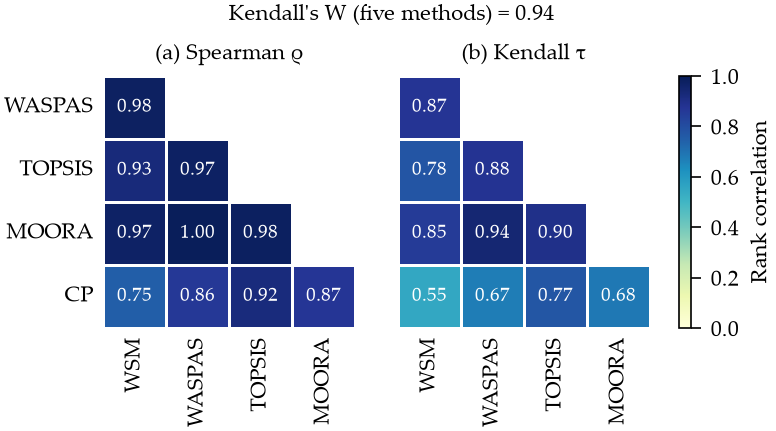

In [13]:
def pair_matrix(column):
    """Symmetric method x method matrix of a column of agreement_df (diagonal = 1)."""
    mat = pd.DataFrame(np.eye(len(methods)), index=methods, columns=methods)
    for pair, value in zip(agreement_df["Pair"], agreement_df[column]):
        a, b = pair.split("–")
        mat.loc[a, b] = mat.loc[b, a] = value
    return mat


panels = {"Spearman_rho": "(a) Spearman ρ", "Kendall_tau": "(b) Kendall τ"}
# Lower triangle only (the matrices are symmetric), without the first row and last column, which would be empty
mask = np.triu(np.ones((len(methods) - 1, len(methods) - 1), dtype=bool), k=1)

fig, axes = plt.subplots(1, len(panels), figsize=(TEXT_WIDTH * 0.6, 2.2), sharey=True, layout="constrained")
for ax, (column, title) in zip(axes, panels.items()):
    sns.heatmap(pair_matrix(column).iloc[1:, :-1], mask=mask, annot=True, fmt=".2f", annot_kws={"fontsize": 7},
                cmap="YlGnBu", vmin=0, vmax=1, square=True, linewidths=0.5, cbar=False, ax=ax)
    ax.set_title(title)
    ax.tick_params(length=0)
    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)
fig.colorbar(axes[0].collections[0], ax=axes, shrink=1.0, label="Rank correlation")
fig.suptitle(f"Kendall's W (five methods) = {W:.2f}", fontsize=8)

save_figure(fig, f"MCDM_Rank_Agreement_{RUN_TAG}")
plt.show()

## 7. Class agreement

In [14]:
def joint_props(a, b, k):
    """Joint proportions (k x k) of two arrays of class codes 0..k-1: rows = a, columns = b."""
    return np.bincount(a * k + b, minlength=k * k).reshape(k, k) / len(a)


def weighted_kappa(cm):
    """Cohen's kappa with linear weights: a disagreement of d classes counts d / (k - 1)."""
    i, j = np.indices(cm.shape)
    disagree = np.abs(i - j) / (len(cm) - 1)
    return 1 - (disagree * cm).sum() / (disagree * np.outer(cm.sum(axis=1), cm.sum(axis=0))).sum()


def krippendorff_alpha_ordinal(codes, k):
    """Krippendorff's alpha, ordinal metric, for an (n_cells x n_methods) array of class codes 0..k-1, no missing values."""
    m = codes.shape[1]
    votes = np.stack([(codes == c).sum(axis=1) for c in range(k)], axis=1)  # methods per class in each cell
    patterns, n_cells = np.unique(votes, axis=0, return_counts=True)  # few distinct patterns: fast and exact
    coincidence = np.einsum("u,uc,uk->ck", n_cells, patterns, patterns) - np.diag(votes.sum(axis=0))
    coincidence = coincidence / (m - 1)
    n_c = coincidence.sum(axis=1)
    cum = np.concatenate([[0], np.cumsum(n_c)])
    lo, hi = np.minimum.outer(range(k), range(k)), np.maximum.outer(range(k), range(k))
    delta = (cum[hi + 1] - cum[lo] - (n_c[:, None] + n_c[None, :]) / 2) ** 2  # ordinal distance between classes
    return 1 - (n_c.sum() - 1) * (coincidence * delta).sum() / (np.outer(n_c, n_c) * delta).sum()


codes = np.column_stack([classified["Jenks"][m].cat.codes.to_numpy() for m in methods]).astype(np.int64)
k = len(CLASS_LABELS)
CLASS_ABBR = ["NS", "LS", "MS", "S", "HS"]

kappa_rows, jaccard_rows = [], []
for i, a in enumerate(methods):
    for j in range(i + 1, len(methods)):
        pair, cm = f"{a}–{methods[j]}", joint_props(codes[:, i], codes[:, j], k)
        kappa_rows.append({"Pair": pair, "Kappa_linear": weighted_kappa(cm)})
        for c, label in enumerate(CLASS_LABELS):
            shared, size_a, size_b = cm[c, c], cm[c, :].sum(), cm[:, c].sum()
            jaccard, jaccard_max = shared / (size_a + size_b - shared), min(size_a, size_b) / max(size_a, size_b)
            jaccard_rows.append({"Pair": pair, "Class": label, "Jaccard": jaccard, "Jaccard_max": jaccard_max,
                                 "Jaccard_rel": jaccard / jaccard_max})
class_kappa_df = pd.DataFrame(kappa_rows)
class_jaccard_df = pd.DataFrame(jaccard_rows)
class_kappa_df.to_csv(table_path("Class_Agreement"), index=False)
class_jaccard_df.to_csv(table_path("Class_Jaccard"), index=False)

alpha = krippendorff_alpha_ordinal(codes, k)
pd.Series({"Krippendorff_alpha_ordinal": alpha}).to_csv(table_path("Class_Concordance"), header=["Value"])

jaccard_wide = {col: class_jaccard_df.pivot(index="Pair", columns="Class", values=col)
                .loc[class_kappa_df["Pair"], CLASS_LABELS].set_axis(CLASS_ABBR, axis=1) for col in ("Jaccard", "Jaccard_max")}
print(f"Krippendorff's alpha, ordinal (five methods): {alpha:.3f}")
display(class_kappa_df.set_index("Pair").join(jaccard_wide["Jaccard"].add_prefix("J_")).round(3))
print("Largest Jaccard possible given the class sizes:")
display(jaccard_wide["Jaccard_max"].round(3))

Krippendorff's alpha, ordinal (five methods): 0.788


,Kappa_linear,J_NS,J_LS,J_MS,J_S,J_HS
Pair,,,,,,
WSM–WASPAS,0.855,0.739,0.646,0.577,0.654,0.733
WSM–TOPSIS,0.463,0.449,0.144,0.092,0.122,0.219
WSM–MOORA,0.769,0.672,0.536,0.420,0.455,0.499
WSM–CP,0.374,0.318,0.159,0.109,0.132,0.223
WASPAS–TOPSIS,0.547,0.564,0.208,0.083,0.122,0.276
WASPAS–MOORA,0.881,0.861,0.750,0.663,0.641,0.631
WASPAS–CP,0.469,0.433,0.179,0.109,0.138,0.284
TOPSIS–MOORA,0.638,0.637,0.309,0.192,0.254,0.439
TOPSIS–CP,0.809,0.675,0.487,0.650,0.817,0.900


Largest Jaccard possible given the class sizes:


,NS,LS,MS,S,HS
Pair,,,,,
WSM–WASPAS,0.823,0.953,0.926,0.917,0.849
WSM–TOPSIS,0.471,0.827,0.962,0.415,0.243
WSM–MOORA,0.736,0.997,0.858,0.851,0.545
WSM–CP,0.426,0.866,0.923,0.422,0.259
WASPAS–TOPSIS,0.572,0.788,0.962,0.452,0.286
WASPAS–MOORA,0.894,0.950,0.926,0.927,0.642
WASPAS–CP,0.518,0.826,0.855,0.460,0.305
TOPSIS–MOORA,0.640,0.830,0.891,0.487,0.445
TOPSIS–CP,0.905,0.955,0.889,0.982,0.936


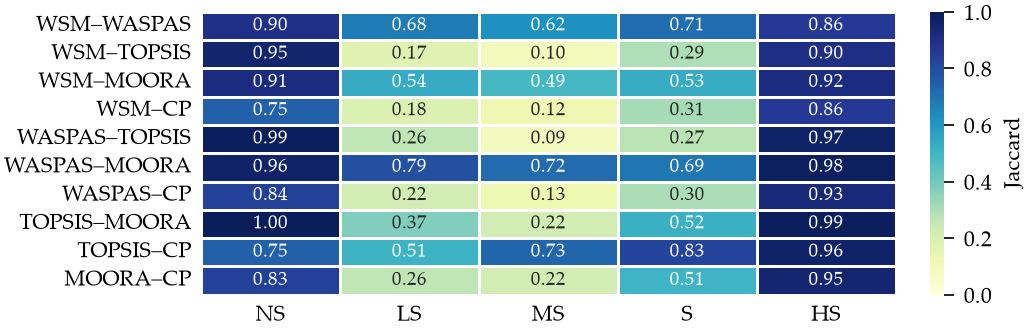

In [15]:
fig, ax = plt.subplots(figsize=(TEXT_WIDTH *0.8 , 1.7), layout="constrained")
sns.heatmap(jaccard_wide["Jaccard"] / jaccard_wide["Jaccard_max"], annot=True, fmt=".2f", annot_kws={"fontsize": 7},
            cmap="YlGnBu", vmin=0, vmax=1, linewidths=0.5, cbar_kws={"label": "Jaccard"}, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(length=0)
ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

save_figure(fig, f"MCDM_Class_Jaccard_{RUN_TAG}")
plt.show()

## 8. Robust suitable areas

The **consensus** region is the land classified *Suitable* or *Highly Suitable* (S/HS) by all five methods.
`SHS_Consensus_Overlap_<run>.csv` and the figure give, for each method, the % of its S/HS area that lies inside the
consensus region. The consensus region is mapped and exported for QGIS.

In [16]:
shs = codes >= CLASS_LABELS.index("Suitable")  # Suitable or Highly Suitable, one column per method
consensus = shs.all(axis=1)

# % of the S/HS area of each method that lies inside the consensus region
consensus_overlap_df = pd.DataFrame({"SHS_in_consensus_pct": 100 * consensus.sum() / shs.sum(axis=0)},
                                    index=pd.Index(methods, name="Method"))
consensus_overlap_df.to_csv(table_path("SHS_Consensus_Overlap"))

print(f"Consensus: {consensus.sum() * CELL_AREA_KM2:,.0f} km² ({100 * consensus.mean():.2f}% of the candidate area)")
display(consensus_overlap_df.round(1))

Consensus: 365,340 km² (11.95% of the candidate area)


,SHS_in_consensus_pct
Method,
WSM,32.2
WASPAS,35.9
TOPSIS,89.9
MOORA,42.9
CP,87.3


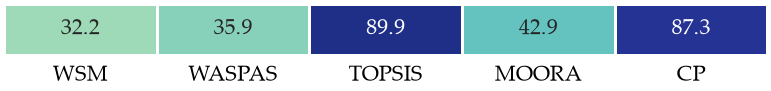

In [17]:
fig, ax = plt.subplots(figsize=(TEXT_WIDTH * 0.6, 0.5), layout="constrained")
sns.heatmap(consensus_overlap_df.T, annot=True, fmt=".1f", annot_kws={"fontsize": 8}, cmap="YlGnBu", vmin=0, vmax=100,
            linewidths=1, cbar=False, ax=ax)
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_yticks([])
ax.tick_params(length=0)
ax.tick_params(axis="x", rotation=0)

save_figure(fig, f"SHS_Consensus_Overlap_{RUN_TAG}")
plt.show()

In [ ]:
# Consensus raster, also exported for QGIS: 0 = outside the study area (NoData), 1 = excluded by the mask,
# 2 = candidate without consensus, 3 = consensus (Suitable/Highly Suitable for all methods)
consensus_arr = np.zeros(anchor.shape, dtype=np.uint8)
consensus_arr[anchor == 1] = 1
consensus_arr[rows_idx, cols_idx] = np.where(consensus, 3, 2)
meta = anchor_meta | {"driver": "GTiff", "dtype": "uint8", "nodata": 0, "count": 1, "compress": "deflate"}
with rasterio.open(map_path("Consensus"), "w", **meta) as dst:
    dst.write(consensus_arr, 1)
display_arr = np.ma.masked_equal(consensus_arr, 0)

map_colors = ["#f0f0f0", "#cccccc", "#1a9641"]
t = anchor_meta["transform"]
extent = (t.c, t.c + t.a * anchor.shape[1], t.f + t.e * anchor.shape[0], t.f)

fig, ax = plt.subplots(figsize=(TEXT_WIDTH, 3), layout="constrained")
ax.imshow(display_arr, cmap=ListedColormap(map_colors), norm=BoundaryNorm([0.5, 1.5, 2.5, 3.5], 3), extent=extent, interpolation="none")

gpd.read_file(study_area_file(P)).to_crs(anchor_meta["crs"]).simplify(1000).plot(ax=ax, facecolor="none", edgecolor="black", linewidth=0.4)

ax.legend(handles=[
    Patch(facecolor=map_colors[2], edgecolor="black", linewidth=0.4, label=f"Consensus Suitability\n({100 * consensus.mean():.2f}%)")
], loc="best", fontsize="small", frameon=False)

km = FuncFormatter(lambda v, _: f"{v / 1000:,.0f}")
ax.xaxis.set_major_formatter(km)
ax.yaxis.set_major_formatter(km)
ax.set_xlabel(f"Easting (km), {crs_label(anchor_meta['crs'])}")
ax.set_ylabel(f"Northing (km), {crs_label(anchor_meta['crs'])}")

save_figure(fig, f"Consensus_Map_{RUN_TAG}")
plt.show()

## 9. Validation against existing projects

Skipped if `[validation] projects` in config.toml is empty or missing, or if no project lies in the candidate area.

In [ ]:
# Needs the existing projects ([validation] projects in config.toml)
RUN_VALIDATION = P.projects is not None and P.projects.exists()
if RUN_VALIDATION:
    projects = gpd.read_file(P.projects).to_crs(anchor_meta["crs"])

    # Candidate cell of each project (candidate cells are sorted by grid position, so a binary search suffices)
    p_rows, p_cols = map(np.asarray, rasterio.transform.rowcol(anchor_meta["transform"], projects.geometry.x, projects.geometry.y))
    grid_h, grid_w = anchor.shape
    cell_keys = rows_idx.astype(np.int64) * grid_w + cols_idx
    project_keys = p_rows.astype(np.int64) * grid_w + p_cols
    pos = np.searchsorted(cell_keys, project_keys).clip(0, len(cell_keys) - 1)
    inside = (p_rows >= 0) & (p_rows < grid_h) & (p_cols >= 0) & (p_cols < grid_w) & (cell_keys[pos] == project_keys)
    RUN_VALIDATION = inside.any()
    if not RUN_VALIDATION:
        print("No project lies inside the candidate area: validation skipped.")
else:
    print("No projects layer ([validation] projects in config.toml): validation skipped.")

if RUN_VALIDATION:
    project_pct = pd.DataFrame({m: classified["Jenks"][m].iloc[pos[inside]].value_counts(normalize=True)
                                   .reindex(CLASS_LABELS, fill_value=0) * 100 for m in methods}).T

    fig, ax = plt.subplots(figsize=(TEXT_WIDTH, 2.4), layout="constrained")
    project_pct.plot.bar(stacked=True, color=CLASS_COLORS, edgecolor="black", linewidth=0.4, width=0.4, ax=ax, legend=False)
    for bars, color in zip(ax.containers, CLASS_COLORS):  # label segments of at least 5 % (thinner ones have no room)
        ax.bar_label(bars, labels=[f"{v:.1f}%" if v >= 5 else "" for v in bars.datavalues], label_type="center",
                     fontsize=7, color="white" if color in ("#d7191c", "#1a9641") else "black")
    ax.set_xlabel("")
    ax.set_ylabel("Projects (%)")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", linestyle=":", linewidth=0.5, alpha=0.7)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[::-1], labels[::-1], title="Suitability class", loc="center left", bbox_to_anchor=(1.01, 0.5), frameon=False)

    save_figure(fig, f"Validation_Projects_{RUN_TAG}")
    plt.show()

In [ ]:
# Validation table: share of projects per class, enrichment over the area share, AUC, Boyce index, binomial test
if RUN_VALIDATION:
    project_cells = pos[inside]  # candidate cell of each project inside the candidate area
    n_projects, n_cells = len(project_cells), len(codes)
    shs_classes = slice(CLASS_LABELS.index("Suitable"), None)

    rows = []
    for i, m in enumerate(methods):
        s = scores_df[m].to_numpy()
        sorted_s, ps = np.sort(s), s[project_cells]
        below = np.searchsorted(sorted_s, ps, "left")
        auc = np.mean((below + 0.5 * (np.searchsorted(sorted_s, ps, "right") - below)) / n_cells)

        area = np.bincount(codes[:, i], minlength=k) / n_cells                  # share expected at random
        observed = np.bincount(codes[project_cells, i], minlength=k) / n_projects
        pe = np.divide(observed, area, out=np.full(k, np.nan), where=area > 0)
        hit, area_shs = observed[shs_classes].sum(), area[shs_classes].sum()
        p = binomtest(round(hit * n_projects), n_projects, area_shs, alternative="greater").pvalue
        rows.append({"Method": m, **{f"{c} (%)": 100 * v for c, v in zip(CLASS_ABBR, observed)},
                     "S+HS projects (%)": 100 * hit, "S+HS area (%)": 100 * area_shs, "Enrichment": hit / area_shs,
                     "P/E (HS)": pe[-1], "AUC": auc, "Boyce": spearmanr(np.arange(k), pe, nan_policy="omit").statistic,
                     "p": f"{p:.1e}"})

    validation_df = pd.DataFrame(rows).set_index("Method").round(2)
    validation_df.to_csv(table_path("Validation_Table"))
    print(f"{n_projects} projects inside the candidate area ({len(projects) - n_projects} outside)\n")
    display(validation_df)